# Gaussian Mixture Models Lab

## Introduction

In this lab, you will apply Gaussian Mixture Models (GMM) to the Breast Cancer Wisconsin Diagnostic dataset, a dataset commonly used for medical diagnosis research. Unlike k-means clustering, which assigns each data point to a single cluster with hard boundaries, GMM uses a probabilistic approach. Instead of a data point being assigned to a single cluster, it is given a probability of belonging to multiple clusters, making GMM a soft clustering technique.

This probabilistic nature of GMM makes it especially valuable in situations where:
- **Cluster boundaries are not well-defined:** Real-world datasets, such as medical or financial data, often have overlapping groups where hard assignments (like k-means) may not capture the full picture.
- **Data follows a Gaussian distribution:** Many natural phenomena, including biological measurements, tend to exhibit normal (Gaussian) distributions, making GMM a powerful tool for uncovering meaningful clusters.
- **Identifying uncertainty in data:** Because GMM provides probabilities rather than strict assignments, it allows us to assess how confidently a data point belongs to a cluster, which is useful for detecting anomalies and ambiguous data points, critical in applications like fraud detection, medical diagnosis, and customer segmentation.

For the lab, you will first preprocess the dataset and determine the optimal number of clusters using the Bayesian Information Criterion (BIC). Then, you will apply GMM clustering and evaluate its effectiveness using the silhouette score. Additionally, you will identify potential anomalies based on low cluster probability scores and compare GMM's performance to k-means clustering to understand how these two approaches differ.

By the end of this lab, you will have gained practical experience in probabilistic clustering, model selection using BIC, and anomaly detection, which are all valuable techniques in data science applications.

### Step 0: Load and Prepare the Dataset

- Import any necessary libraries, including `GaussianMixture` from `sklearn.mixture`.
- Load the Breast Cancer dataset from `sklearn.datasets.load_breast_cancer()`.
- Create a DataFrame with the feature data.
- Remove the labels from the dataset to simulate an unsupervised learning scenario.

In [1]:
# CodeGrade step0

# Import any useful libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.datasets import load_breast_cancer

In [2]:
# CodeGrade step0

# Load the dataset:
cancer = load_breast_cancer()

# Create a DataFrame containing the features:
df = pd.DataFrame(cancer.data, columns = cancer.feature_names)

# Create a separate feature-only (meaning no labels) DataFrame for unsupervised
# learning:
df_unlabeled = df.copy()

### Step 1: Rescale the Data

Standardize the dataset before applying GMM.

- Use `StandardScaler()` from `sklearn.preprocessing` to standardize all the features.
- Fit the scaler to the dataset and transform it into a new variable called `df_scaled`.
- Ensure that `df_scaled` retains the same shape as the original data.

In [3]:
# CodeGrade step1

# Standardize the features:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_unlabeled)

# Check that the shape of `df_scaled` is the same as the shape of
# `df_unlabeled`:
print(f"Shape of original unlabeled data: {df_unlabeled.shape}")
print(f"Shape of standardized data: {df_scaled.shape}")

Shape of original unlabeled data: (569, 30)
Shape of standardized data: (569, 30)


### Step 2: Determine the Optimal Number of Components (BIC & AIC)

Use the Bayesian Information Criterion (BIC) and the Akaike Information Criterion (AIC) to find the best number of clusters.

- Initialize two empty lists: `bic_scores` and `aic_scores`.
- Loop over values of k from 1 to 9:
    - Train a `GaussianMixture` model with the current k components, `random_state = 42`, and `n_init = 10`.
    - Fit the model to `df_scaled` and store the BIC and AIC scores.
- Compute and return the difference between the sum of BIC scores and the sum of AIC scores, rounded to zero decimal places.

In [4]:
# CodeGrade step2

# Initialize two empty lists to store the BIC and AIC scores:
bic_scores = []
aic_scores = []
k_values = range(1, 10)

# Loop over values of k from 1-9:
for k in k_values:
    gmm = GaussianMixture(n_components = k, random_state = 42, n_init = 10)
    gmm.fit(df_scaled)
    bic_scores.append(gmm.bic(df_scaled))
    aic_scores.append(gmm.aic(df_scaled))

# Calculate and return the difference in sums:
print(f"Difference in sum of BIC scores and AIC scores: {sum(bic_scores) - 
      sum(aic_scores):.0f}")

Difference in sum of BIC scores and AIC scores: 96916


Plot the BIC score to visualize the optimal k:
- X-axis: Number of components (k).
- Y-axis: BIC score.
- Use `marker = "o"` and `linestyle = "-"`.

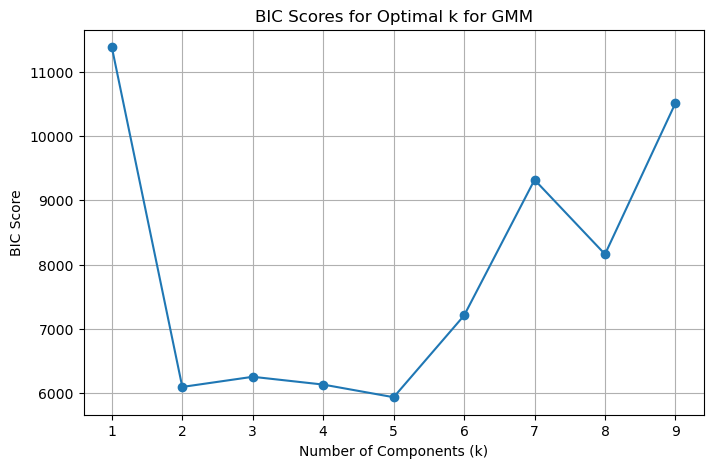

In [5]:
# Plot BIC scores to find the optimal K:
plt.figure(figsize = (8, 5))
plt.plot(k_values, bic_scores, marker = "o", linestyle = "-")
plt.xlabel("Number of Components (k)")
plt.ylabel("BIC Score")
plt.title("BIC Scores for Optimal k for GMM")
plt.grid(True)
plt.show()

### Step 3: Perform GMM Clustering

Apply GMM clustering using the best k from Step 2.

- Set `optimal_k = 2` (determined from the BIC analysis).
- Train a `GaussianMixture` model with `optimal_k`, `random_state = 42`, and `n_init = 10`.
- Assign cluster labels to a new column called `df_unlabeled["GMM_Cluster"]`.
- Compute and store the maximum cluster probability for each sample in `df_unlabeled["Cluster_Probability"]`.
- Compute the silhouette score and return it rounded to four decimal places.

In [6]:
# CodeGrade step3

# Apply GMM clustering with the optimal k from specified in Step 3 (even though
# the lowest BIC actually occurs at k = 5):
optimal_k = 2
gmm = GaussianMixture(n_components = optimal_k, random_state = 42, n_init = 10)
gmm.fit(df_scaled)

# Predict cluster labels:
df_unlabeled["GMM_Cluster"] = gmm.predict(df_scaled)

# Predict the maximum cluster probability for each sample:
df_unlabeled["Cluster_Probability"] = gmm.predict_proba(df_scaled).max(axis = 1)

# Validate clustering quality using the silhouette score:
silhouette_avg = silhouette_score(df_scaled, df_unlabeled["GMM_Cluster"])

# Return the silhouette score rounded to four decimal places:
round(silhouette_avg, 4)

0.3145

### Step 4: Identify Anomalies

Detect outliers using cluster probability scores.

- Compute the 5th percentile of `df_unlabeled["Cluster_Probability"]`.
- Define anomalies as all data points below this threshold.
- Return the number of anomalies detected.

In [7]:
# CodeGrade step4

# Define anomaly threshold (5th percentile):
threshold = np.percentile(df_unlabeled["Cluster_Probability"], 5)

# Anomalies are points below that threshold:
anomalies = df_unlabeled["Cluster_Probability"] < threshold

# Return the number of anomalies:
anomalies.sum()

29

### Step 5: Compare GMM with K-Means

Compare cluster assignments and visualize results.

- Train a k-means model using the same `optimal_k = 2` as GMM.
- Assign cluster labels to a new column called `df_unlabeled["KMeans_Cluster"]`.
- Create a crosstab of GMM and k-means cluster assignments and return its shape.

In [8]:
# CodeGrade step5

# Apply k-means clustering with the same optimal k as the GMM:
kmeans = KMeans(n_clusters = optimal_k, random_state = 42, n_init = 10)
df_unlabeled["KMeans_Cluster"] = kmeans.fit_predict(df_scaled)

# Compare clustering assignments using a contingency table:
comparison = pd.crosstab(df_unlabeled["GMM_Cluster"], 
                         df_unlabeled["KMeans_Cluster"])
print(comparison)

# Return the shape of the table:
comparison.shape

KMeans_Cluster    0    1
GMM_Cluster             
0                25  189
1               350    5


(2, 2)

Apply PCA with `n_components = 2` to reduce `df_scaled` to two dimensions.

In [9]:
# Create a PCA model with `n_components = 2`:
pca = PCA(n_components = 2)

# Transform the standardized data to get the principal components, and store
# the result in a DataFrame:
df_pca = pd.DataFrame(data = pca.fit_transform(df_scaled), columns = 
                      ["PC1", "PC2"])

Create a scatter plot of the GMM clustering results in the two principal components:
- X-axis: Principal Component 1.
- Y-axis: Principal Component 2.
- Color the points based on their assigned GMM cluster.
- Use `cmap = "viridis"`, `marker = "o"`, and `edgecolor = "k"`.
- Add a color bar for cluster labels.

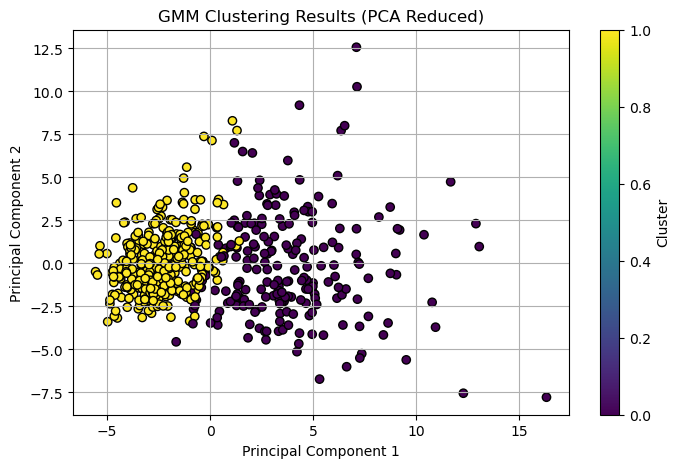

In [10]:
# Scatter plot of GMM clusters in the first two principal components:
plt.figure(figsize = (8, 5))
plt.scatter(df_pca["PC1"], df_pca["PC2"], c = df_unlabeled["GMM_Cluster"], cmap 
            = "viridis", marker = "o", edgecolor = "k")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("GMM Clustering Results (PCA Reduced)")
plt.colorbar(label = "Cluster")
plt.grid(True)
plt.show()

Create another plot to overlay the anomalies:
- Mark anomalies with red "x" symbols.

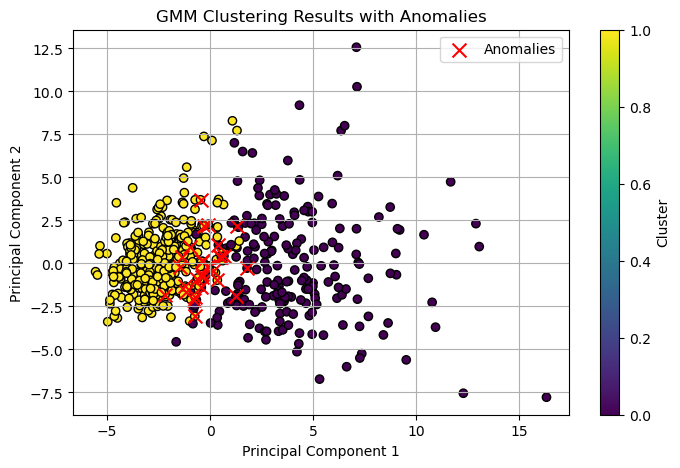

In [11]:
# Plot GMM clusters:
plt.figure(figsize = (8, 5))
plt.scatter(df_pca["PC1"], df_pca["PC2"], c = df_unlabeled["GMM_Cluster"], cmap 
            = "viridis", marker = "o", edgecolor = "k")

# Overlay anomalies using their PCA coordinates:
plt.scatter(df_pca.loc[anomalies, "PC1"], df_pca.loc[anomalies, "PC2"], color = 
            "red", marker = "x", s = 100, label = "Anomalies")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("GMM Clustering Results with Anomalies")
plt.colorbar(label = "Cluster")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Calculate the k-means silhouette score for the k-means cluster model (not
# part of the lab, but useful for comparison):
kmeans_silhouette = silhouette_score(df_scaled, df_unlabeled["KMeans_Cluster"])

print(f"GMM Silhouette Score: {silhouette_avg:.4f}")
print(f"K-Means Silhouette Score: {kmeans_silhouette:.4f}")

GMM Silhouette Score: 0.3145
K-Means Silhouette Score: 0.3434
